In [1]:
!pip install lmfit


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import os
import scipy
from scipy.optimize import curve_fit
import numpy as np
import csv
from scipy.stats import linregress

from lmfit import Minimizer, Parameters, report_fit
import asteval
import uncertainties

In [3]:
file = "Calib.txt"
yellow_basic = "./Measurment Data/Yellow Lines/579nm2s100F Calibration.dat"
yellow_full = "./Measurment Data/Yellow Lines/579nm2s100F Without Pol 28A.dat"
yellow_pol90 = "./Measurment Data/Yellow Lines/579nm2s100F With Pol 90° 28A.dat"
yellow_pol180 = "./Measurment Data/Yellow Lines/579nm2s100F With Pol 180° 28A.dat"
DarkFrame1 = "./Measurment Data/Dark Frames/2s1000F.dat"
DarkFrame2 = "./Measurment Data/Dark Frames/282ms500F.dat"
green_basic = "./Measurment Data/Green Line/Calibration.dat"
green_full = "./Measurment Data/Green Line/Without Pol 27A.dat"
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 27A.dat"
green_pol180 = "./Measurment Data/Green Line/With Pol 180° 27A.dat"

In [4]:
def read_mag_calib(filename):
    
    current = []
    fieldstrength = []
    
    with open(filename, newline="") as f:
        reader = csv.reader(f)
        next(reader) #skips header
        for row in reader:
            data = row[0].split("\t")
            current.append(int(data[0]))
            fieldstrength.append(int(data[1]))
    return current, fieldstrength

def get_mag_strength(current):
    current_calib, fieldstrength = read_mag_calib(file)
    for i in current_calib:
        if current_calib[i] == current:
            mag = fieldstrength[i]/1000 #conversion to Tesla
            mag *= mubohr * 6.241509074461E+18 #Convert Tesla to Energy in eV
            mag *= 1.0E6 #Convert to mueV 
            return mag
        
def read_image(filepath):
    image = []
    with open(filepath, newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            pixelrow = np.array(row[0].split("\t"))
            image.append(pixelrow.astype(int))
        return np.array(image)
    
def image_line(image, pixelstart, width):
    line = []
    for i in range(len(image)):
        line.append(image[i][pixelstart:pixelstart+width].sum())
    return np.array(line)

def lorentzian(x, amplitude, center, gamma):
    return amplitude * gamma**2 / ((x - center)**2 + gamma**2)

def fit_lorentizian(x_bounds, lineOut): #x_bounds im doppeltem array: [[start,ende],[start,ende]]
    x = np.linspace(0,len(lineOut),len(lineOut))
    
    fit_params_popt = []
    fit_params_pcov = []
    
    for param in x_bounds:
        #https://plotivy.app/techniques/lorentzian-fitting
        bounds = ([0, x.min(), 0.1], [np.inf, x.max(), np.inf])
        popt, pcov = curve_fit(lorentzian, x[param[0]:param[1]], lineOut[param[0]:param[1]], p0=[lineOut.max(), x[np.argmax(lineOut)], 5.0], bounds=bounds)
        
        fit_params_popt.append(popt)
        fit_params_pcov.append(pcov)
        
    return fit_params_popt, fit_params_pcov

def get_lorentzian(lineOut, fits_popt):
    x = np.linspace(0,len(lineOut),len(lineOut))
    
    lorentzians = []
    
    for popt in fits_popt:
        y_fit = lorentzian(x, *popt)
        lorentzians.append(y_fit)
        
    return lorentzians

def lorentzian_res(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of a lorentzian function"""
    back = params['back']
    amp = params['amp']
    gamma = params['gamma']
    x0 = params['x0']

    model = back + amp * gamma**2/ ((x - x0)**2 + gamma**2) 

    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data

def FP_lorentzian(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of 6 lorentzian peaks"""
    
    back = params['back']
    model = back
    
    for i in range(1,int((len(params)-1)/3)+1):
        a = "amp" + str(i)
        g = "gamma" + str(i)
        x0 = "x0" + str(i)
        model += params[a] * params[g]**2/ ((x - params[x0])**2 + params[g]**2)
    
    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data

def LM_Lorentzian(params,x):
    back = params['back']
    
    fits = []
    
    for i in range(1,int((len(params)-1)/3)+1):
        a = "amp" + str(i)
        g = "gamma" + str(i)
        x0 = "x0" + str(i)
        y_fit = lorentzian(x, params[a], params[x0], params[g])
        fits.append(y_fit)
    fits = np.array(fits)
    fits += back / len(fits)
    return fits

def Convert_Energy(pixel, focal, wavelength, pixel_dev, focal_dev, centerpixel_dev):
    energy = -(pixel - centerpixel) * 3.75e-6
    energy *= energy
    energy *= lambda2eV
    energy *= 1.0E6 
    energy /= 2 * wavelength * (focal ** 2)
    
    focal_factor = 2*focal_dev/focal
    pixel_err = 2*np.sqrt(pixel_dev**2 + centerpixel_dev**2)/(-(pixel - centerpixel))
    error = energy * np.sqrt(focal_factor**2 + pixel_err**2)
    
    return energy, error

In [5]:
current, fieldstrength = read_mag_calib(file)

#plt.plot(current, fieldstrength)  
#plt.scatter(current, fieldstrength)  
#plt.title("Magnetic Field Calibration")
#plt.xlabel("Current I")
#plt.ylabel("Magnetic Fieldstrength mT")
#plt.show()

In [6]:
DarkFrame_yellow = read_image(DarkFrame1)

yellow_basic_image = read_image(yellow_basic) - DarkFrame_yellow/10
yellow_basic_image[yellow_basic_image < 100] = 0
yellow_basic_image = yellow_basic_image / yellow_basic_image.max()

yellow_full_image = read_image(yellow_full) - DarkFrame_yellow/10
yellow_full_image[yellow_full_image < 100] = 0
yellow_full_image = yellow_full_image / yellow_full_image.max()

yellow_pol90_image = read_image(yellow_pol90) - DarkFrame_yellow/10
yellow_pol90_image[yellow_pol90_image < 100] = 0
yellow_pol90_image = yellow_pol90_image / yellow_pol90_image.max()

yellow_pol180_image = read_image(yellow_pol180) - DarkFrame_yellow/10
yellow_pol180_image[yellow_pol180_image < 100] = 0
yellow_pol180_image = yellow_pol180_image / yellow_pol180_image.max()


#plt.imshow(yellow_basic_image)
##plt.savefig('yellow_basic_image.png')
#plt.show()
#
#plt.imshow(yellow_full_image)
##plt.savefig('yellow_full_image.png')
#plt.show()
#
#plt.imshow(yellow_pol90_image)
##plt.savefig('yellow_pol90_image.png')
#plt.show()
#
#plt.imshow(yellow_pol180_image)
##plt.savefig('yellow_pol180_image.png')
#plt.show()


In [7]:
ImageData = yellow_basic_image
lineOut = image_line(ImageData, 500, 15)
lineOut_normal = lineOut / max(lineOut)

bounds = [[800,910],[680,750],[580,630],[500,550],[420,470],[350,410],[300,340],[240,280],[190,210],[140,165],[90,120],[40,80],[0,30]]

fit_popt, fit_pcov = fit_lorentizian(bounds, lineOut_normal)
fits = get_lorentzian(lineOut_normal, fit_popt)

#plt.imshow(ImageData)
#plt.savefig('Image-DarkFrame.png')
#plt.show()


view = [0,35]
view = [0,len(lineOut)]

plt.scatter(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],lineOut_normal[view[0]:view[1]])
for y_fit in fits:
    plt.plot(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],y_fit[view[0]:view[1]],color='red')
plt.show()

radii = []

for i in range(len(fit_popt)):
    radii.append(fit_popt[i]
radii = np.array(radii)[1])
radii -= 1119.4087745576242   #offset to center
radii *= 3.75e-6    #convert pixel to distance
radii *= -1 # kein physikalischer hintergrund nur damit es nicht negativ ist
radii = radii **2

index = 1

wavelength = 579e-9 
d = 2.442e-3 


x = np.arange(len(radii))
fit = linregress(x[index:], radii[index:])

pars, cov = np.polyfit(x=x, y=radii, deg=1, w=None, cov=True)
focus= np.sqrt(pars[0]*d/wavelength) 
y_fit = pars[0] * x + pars[1]

residuals = radii - y_fit

focal = np.sqrt((pars[0]*d) / wavelength)

print("f=",focal*1000,"mm")
print("Delta_f=",focal*np.sqrt(np.diag(cov)[0])/pars[0]*0.5*1000, "mm")   # uncertainty propagation from slope to focus

Results = []
Results.append(dict(Name="Focal Length", Value=focal, Error=focal*np.sqrt(np.diag(cov)[0])/pars[0]*0.5))


plt.scatter(x[index:],radii[index:])
plt.plot(x[index:],y_fit[index:])
plt.show()

plt.scatter(x[index:],residuals[index:])
plt.show()


SyntaxError: invalid syntax. Perhaps you forgot a comma? (3989910348.py, line 26)

In [ ]:
mubohr= 9.2740e-24       # Bohr magneton
hbar= 1.05457e-34      
ee=   1.60218e-19        # elementary charge
cc= 299792458            # speed of light

lambda2eV= cc*hbar/ee*np.pi*2   #conversion between wavelength (in meter) and energy (in eV):  Energy= lambda2eV / lambda

x = np.linspace(0,len(lineOut),len(lineOut))
centerpixel = 1119.4087745576242
radius_0A_lin = -(x  - centerpixel) * 3.75e-6
energyaxis = radius_0A_lin**2*lambda2eV/(2*wavelength*focal**2)*1e6

plt.rcParams.update({'font.size': 16})              # changes font size for plots
plt.rc('xtick', labelsize=14)   
plt.rc('ytick', labelsize=14)   
plt.figure(figsize=(7,5))
plt.ylabel('Energy (µeV)', fontsize=14)
plt.xlabel('Radius (m)', fontsize=14)

plt.plot(radius_0A_lin,energyaxis,'r', markersize=3,label='I=0A') 
plt.tight_layout()

In [ ]:
green_full_image = read_image(yellow_full) - read_image(DarkFrame1)/10
green_full_line = image_line(green_full_image, 500, 15)
green_full_line_normal = green_full_line / max(green_full_line)

green_pol90_image = read_image(yellow_pol90) - read_image(DarkFrame1)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)

green_pol180_image = read_image(yellow_pol180) - read_image(DarkFrame1)/10
green_pol180_line = image_line(green_pol180_image, 500, 15)
green_pol180_line_normal = green_pol180_line / max(green_pol180_line)

x = np.linspace(0,len(green_full_line),len(green_full_line))
centerpixel = 1119.4087745576242
radius_0A_lin = -(x  - centerpixel) * 3.75e-6
energyaxis = radius_0A_lin**2*lambda2eV/(2*wavelength*focal**2)*1e6

In [ ]:
ImageData = read_image(yellow_basic) #- read_image(DarkFrame2)
DarkOut = image_line(read_image(DarkFrame1), 500, 15)
lineOut = image_line(ImageData, 500, 15)
lineOut_normal = lineOut / max(lineOut)
Background = np.average(DarkOut)  
x = np.linspace(0,len(lineOut),len(lineOut))


#plt.imshow(green_basic_image)
#plt.savefig('green_basic_image.png')
#plt.show()
#
plt.imshow(green_full_image)
#plt.savefig('green_full_image.png')
plt.colorbar()
plt.show()
#
#plt.imshow(green_pol90_image)
#plt.savefig('green_pol90_image.png')
#plt.show()
#
#plt.imshow(green_pol180_image)
#plt.savefig('green_pol180_image.png')
#plt.show()

radii = []

for i in range(len(fit_popt)):
    radii.append(fit_popt[i][1])
    
peaks = radii
width = 7

green_27A_params = Parameters()
green_27A_params.add('back', value=Background*0.05, vary = True)

green_27A_params.add('amp1', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma1', value = 0.00005, vary = True)
green_27A_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = False)

green_27A_params.add('amp2', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma2', value = 0.00005, vary = True)
green_27A_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = False)

green_27A_params.add('amp3', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma3', value = 0.00005, vary = True)
green_27A_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = False)

green_27A_params.add('amp4', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma4', value = 0.00005, vary = True)
green_27A_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = False)

green_27A_params.add('amp5', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma5', value = 0.00005, vary = True)
green_27A_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = False)

green_27A_params.add('amp6', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma6', value = 0.00005, vary = True)
green_27A_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = False)

green_27A_params.add('amp7', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma7', value = 0.00005, vary = True)
green_27A_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = False)

green_27A_params.add('amp8', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma8', value = 0.00005, vary = True)
green_27A_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = False)

green_27A_params.add('amp9', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma9', value = 0.00005, vary = True)
green_27A_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = False)

green_27A_params.add('amp10', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma10', value = 0.00005, vary = True)
green_27A_params.add('x010', value = peaks[9], min=(peaks[9]-width), max=(peaks[9]+width), vary = False)

green_27A_params.add('amp11', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma11', value = 0.00005, vary = True)
green_27A_params.add('x011', value = peaks[10], min=(peaks[10]-width), max=(peaks[10]+width), vary = False)

green_27A_params.add('amp12', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma12', value = 0.00005, vary = True)
green_27A_params.add('x012', value = peaks[11], min=(peaks[11]-width), max=(peaks[1]+width), vary = False)

green_27A_params.add('amp13', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma13', value = 0.00005, vary = True)
green_27A_params.add('x013', value = peaks[12], min=(peaks[12]-width), max=(peaks[12]+width), vary = False)

In [ ]:
Kill_me = Minimizer(FP_lorentzian,green_27A_params,fcn_args=(x,lineOut))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(lineOut))

view = [0,900]
view = [0,len(lineOut)]

plt.scatter(x[view[0]:view[1]],lineOut[view[0]:view[1]])
for y_fit in fits:
    fit += y_fit
plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
plt.show()

report_fit(resultlor, show_correl=False, sort_pars=True)


Results.append(dict(Name="Spectral Resolution (Gamma) avg.", Value=np.average(average), Error=np.average(error)))

In [ ]:
peaks = [810, 850, 930]
width = 15

green_27A_params = Parameters()
green_27A_params.add('back', value=0, vary = True)

green_27A_params.add('amp1', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma1', value = 0.00005, vary = True)
green_27A_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_27A_params.add('amp2', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma2', value = 0.00005, vary = True)
green_27A_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_27A_params.add('amp3', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma3', value = 0.00005, vary = True)
green_27A_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

In [ ]:
bounds = [770,960]
Kill_me = Minimizer(FP_lorentzian,green_27A_params,fcn_args=(x[bounds[0]:bounds[1]],green_full_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_full_line))

view = bounds
#view = [0,len(lineOut)]

plt.scatter(x[view[0]:view[1]],green_full_line[view[0]:view[1]])
for y_fit in fits:
    fit += y_fit
plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
plt.show()

In [ ]:
x1_pi_fits = []
x1_pi_fits_dev = []

x2_pi_fits = []
x2_pi_fits_dev = []

x3_pi_fits = []
x3_pi_fits_dev = []

In [ ]:
green_pol90 = "./Measurment Data/Yellow Lines/579nm2s100F With Pol 90° 28A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)


peaks = [810, 850, 930]
width = 15

green_pol90_params = Parameters()
green_pol90_params.add('back', value=0, vary = True)

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)


bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]

plt.scatter(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
for y_fit in fits:
    fit += y_fit
plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
plt.show()

x1_pi_fits.append(resultlor.params["x01"].value)
x1_pi_fits_dev.append(resultlor.params["x01"].stderr)

x2_pi_fits.append(resultlor.params["x02"].value)
x2_pi_fits_dev.append(resultlor.params["x02"].stderr)

x3_pi_fits.append(resultlor.params["x03"].value)
x3_pi_fits_dev.append(resultlor.params["x03"].stderr)


In [ ]:
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 18A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)


green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.5, vary = True)

peaks = [830, 840, 850]
width = 7

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)


bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

#view = bounds
#
#plt.scatter(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_pi_fits.append(resultlor.params["x01"].value)
x1_pi_fits_dev.append(resultlor.params["x01"].stderr)

x2_pi_fits.append(resultlor.params["x02"].value)
x2_pi_fits_dev.append(resultlor.params["x02"].stderr)

x3_pi_fits.append(resultlor.params["x03"].value)
x3_pi_fits_dev.append(resultlor.params["x03"].stderr)


In [ ]:
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 21A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)


green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.5, vary = True)

peaks = [830, 840, 850]
width = 5

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)


bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

#view = bounds
#
#plt.scatter(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_pi_fits.append(resultlor.params["x01"].value)
x1_pi_fits_dev.append(resultlor.params["x01"].stderr)

x2_pi_fits.append(resultlor.params["x02"].value)
x2_pi_fits_dev.append(resultlor.params["x02"].stderr)

x3_pi_fits.append(resultlor.params["x03"].value)
x3_pi_fits_dev.append(resultlor.params["x03"].stderr)


In [ ]:
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 24A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)


green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.5, vary = True)

peaks = [820, 840, 860]
width = 7

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)


bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

#view = bounds
#
#plt.scatter(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_pi_fits.append(resultlor.params["x01"].value)
x1_pi_fits_dev.append(resultlor.params["x01"].stderr)

x2_pi_fits.append(resultlor.params["x02"].value)
x2_pi_fits_dev.append(resultlor.params["x02"].stderr)

x3_pi_fits.append(resultlor.params["x03"].value)
x3_pi_fits_dev.append(resultlor.params["x03"].stderr)


In [ ]:
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 27A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)


green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.5, vary = True)

peaks = [820, 840, 860]
width = 7

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)


bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

#view = bounds
#view = [0,len(lineOut)]

#plt.scatter(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_pi_fits.append(resultlor.params["x01"].value)
x1_pi_fits_dev.append(resultlor.params["x01"].stderr)

x2_pi_fits.append(resultlor.params["x02"].value)
x2_pi_fits_dev.append(resultlor.params["x02"].stderr)

x3_pi_fits.append(resultlor.params["x03"].value)
x3_pi_fits_dev.append(resultlor.params["x03"].stderr)


In [8]:
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 30A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)


green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.5, vary = True)

peaks = [820, 840, 860]
width = 10

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)


bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]

#plt.scatter(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_pi_fits.append(resultlor.params["x01"].value)
x1_pi_fits_dev.append(resultlor.params["x01"].stderr)

x2_pi_fits.append(resultlor.params["x02"].value)
x2_pi_fits_dev.append(resultlor.params["x02"].stderr)

x3_pi_fits.append(resultlor.params["x03"].value)
x3_pi_fits_dev.append(resultlor.params["x03"].stderr)


NameError: name 'Background' is not defined

In [ ]:
centerpixel = 1119.87117
centerpixel_dev = 1.62799933


energy1, error1 = Convert_Energy(np.array(x1_pi_fits), Results[0]["Value"], wavelength, np.array(x1_pi_fits_dev), Results[0]["Error"], centerpixel_dev)
energy2, error2 = Convert_Energy(np.array(x2_pi_fits), Results[0]["Value"], wavelength, np.array(x2_pi_fits_dev), Results[0]["Error"], centerpixel_dev)
energy3, error3 = Convert_Energy(np.array(x3_pi_fits), Results[0]["Value"], wavelength, np.array(x3_pi_fits_dev), Results[0]["Error"], centerpixel_dev)

x = np.array([get_mag_strength(15), get_mag_strength(18), get_mag_strength(21), get_mag_strength(24), get_mag_strength(27), get_mag_strength(30)])

diff12 = energy1 - energy2
sigma12 = np.sqrt(error1**2 + error2**2)

diff32 = energy3 - energy2
sigma32 = np.sqrt(error3**2 + error2**2)

(coeffs12, cov12) = np.polyfit(x, diff12, deg=1, w=1 / sigma12, cov="unscaled")
slope12, intercept12 = coeffs12
slope12_dev, intercept12_dev = np.sqrt(np.diag(cov12))

(coeffs32, cov32) = np.polyfit(x, diff32, deg=1, w=1 / sigma32, cov="unscaled")
slope32, intercept32 = coeffs32
slope32_dev, intercept32_dev = np.sqrt(np.diag(cov32))

x_pi_fit = np.linspace(x.min(), x.max(), 200)

plt.rcParams['text.usetex'] = True
plt.errorbar(x, diff12, yerr=sigma12, fmt="o", label="Energy 1")
plt.plot(x_pi_fit, slope12 * x_pi_fit + intercept12, label="Fit E1")

plt.errorbar(x, diff32, yerr=sigma32, fmt="o", label="Energy 3")
plt.plot(x_pi_fit, slope32 * x_pi_fit + intercept32, label="Fit E3")

plt.xlabel(r"\textbf{$\mu_B  B  \: in  \: \mu eV$}")
plt.ylabel(r"\textbf{$Relative \: Energy \: in \: \mu eV$}")
plt.legend()
plt.show()

print(slope12)
print(slope32)

In [ ]:
x1_fits = []
x1_fits_dev = []

x2_fits = []
x2_fits_dev = []

x3_fits = []
x3_fits_dev = []

x4_fits = []
x4_fits_dev = []

x5_fits = []
x5_fits_dev = []

x6_fits = []
x6_fits_dev = []

x7_fits = []
x7_fits_dev = []

x8_fits = []
x8_fits_dev = []

x9_fits = []
x9_fits_dev = []

In [ ]:
green_pol90 = "./Measurment Data/Green Line/Without Pol 15A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)
x = np.linspace(0,len(green_pol90_line),len(green_pol90_line))

peaks = [770, 790, 810, 830, 840, 850, 870, 890, 910]
width = 15

green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.1,min=0,max=Background*2, vary = True)

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

green_pol90_params.add('amp4', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma4', value = 0.00005, vary = True)
green_pol90_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = True)

green_pol90_params.add('amp5', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma5', value = 0.00005, vary = True)
green_pol90_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = True)

green_pol90_params.add('amp6', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma6', value = 0.00005, vary = True)
green_pol90_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = True)

green_pol90_params.add('amp7', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma7', value = 0.00005, vary = True)
green_pol90_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = True)

green_pol90_params.add('amp8', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma8', value = 0.00005, vary = True)
green_pol90_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = True)

green_pol90_params.add('amp9', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma9', value = 0.00005, vary = True)
green_pol90_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = True)

bounds = [745,930]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize(method='least_squares')
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]
#plt.plot(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_fits.append(resultlor.params["x01"].value)
x1_fits_dev.append(min(20,resultlor.params["x01"].stderr))

x2_fits.append(resultlor.params["x02"].value)
x2_fits_dev.append(min(20,resultlor.params["x02"].stderr))

x3_fits.append(resultlor.params["x03"].value)
x3_fits_dev.append(min(20,resultlor.params["x03"].stderr))

x4_fits.append(resultlor.params["x04"].value)
x4_fits_dev.append(min(20,resultlor.params["x04"].stderr))

x5_fits.append(resultlor.params["x05"].value)
x5_fits_dev.append(min(20,resultlor.params["x05"].stderr))

x6_fits.append(resultlor.params["x06"].value)
x6_fits_dev.append(min(20,resultlor.params["x06"].stderr))

x7_fits.append(resultlor.params["x07"].value)
x7_fits_dev.append(min(20,resultlor.params["x07"].stderr))

x8_fits.append(resultlor.params["x08"].value)
x8_fits_dev.append(min(20,resultlor.params["x08"].stderr))

x9_fits.append(resultlor.params["x09"].value)
x9_fits_dev.append(min(20,resultlor.params["x09"].stderr))

In [ ]:
green_pol90 = "./Measurment Data/Green Line/Without Pol 18A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)
x = np.linspace(0,len(green_pol90_line),len(green_pol90_line))

peaks = [770, 790, 810, 830, 840, 850, 870, 890, 910]
width = 12

green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.1,min=0,max=Background*2, vary = True)

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

green_pol90_params.add('amp4', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma4', value = 0.00005, vary = True)
green_pol90_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = True)

green_pol90_params.add('amp5', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma5', value = 0.00005, vary = True)
green_pol90_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = True)

green_pol90_params.add('amp6', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma6', value = 0.00005, vary = True)
green_pol90_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = True)

green_pol90_params.add('amp7', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma7', value = 0.00005, vary = True)
green_pol90_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = True)

green_pol90_params.add('amp8', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma8', value = 0.00005, vary = True)
green_pol90_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = True)

green_pol90_params.add('amp9', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma9', value = 0.00005, vary = True)
green_pol90_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = True)

bounds = [765,915]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize(method='least_squares')
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

#view = bounds
#plt.plot(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

#x1_fits.append(resultlor.params["x01"].value)
#x1_fits_dev.append(min(5,resultlor.params["x01"].stderr))
#
#x2_fits.append(resultlor.params["x02"].value)
#x2_fits_dev.append(min(5,resultlor.params["x02"].stderr))
#
#x3_fits.append(resultlor.params["x03"].value)
#x3_fits_dev.append(min(5,resultlor.params["x03"].stderr))
#
#x4_fits.append(resultlor.params["x04"].value)
#x4_fits_dev.append(min(5,resultlor.params["x04"].stderr))
#
#x5_fits.append(resultlor.params["x05"].value)
#x5_fits_dev.append(min(5,resultlor.params["x05"].stderr))
#
#x6_fits.append(resultlor.params["x06"].value)
#x6_fits_dev.append(min(5,resultlor.params["x06"].stderr))
#
#x7_fits.append(resultlor.params["x07"].value)
#x7_fits_dev.append(min(5,resultlor.params["x07"].stderr))
#
#x8_fits.append(resultlor.params["x08"].value)
#x8_fits_dev.append(min(5,resultlor.params["x08"].stderr))
#
#x9_fits.append(resultlor.params["x09"].value)
#x9_fits_dev.append(min(5,resultlor.params["x09"].stderr))

In [9]:
green_pol90 = "./Measurment Data/Green Line/Without Pol 21A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)
x = np.linspace(0,len(green_pol90_line),len(green_pol90_line))

peaks = [760, 780, 800, 820, 840, 860, 880, 900, 920]
width = 13

green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.1,min=0,max=Background*2, vary = True)

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

green_pol90_params.add('amp4', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma4', value = 0.00005, vary = True)
green_pol90_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = True)

green_pol90_params.add('amp5', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma5', value = 0.00005, vary = True)
green_pol90_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = True)

green_pol90_params.add('amp6', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma6', value = 0.00005, vary = True)
green_pol90_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = True)

green_pol90_params.add('amp7', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma7', value = 0.00005, vary = True)
green_pol90_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = True)

green_pol90_params.add('amp8', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma8', value = 0.00005, vary = True)
green_pol90_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = True)

green_pol90_params.add('amp9', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma9', value = 0.00005, vary = True)
green_pol90_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = True)

bounds = [745,930]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize(method='least_squares')
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]
#plt.plot(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_fits.append(resultlor.params["x01"].value)
x1_fits_dev.append(min(20,resultlor.params["x01"].stderr))

x2_fits.append(resultlor.params["x02"].value)
x2_fits_dev.append(min(20,resultlor.params["x02"].stderr))

x3_fits.append(resultlor.params["x03"].value)
x3_fits_dev.append(min(20,resultlor.params["x03"].stderr))

x4_fits.append(resultlor.params["x04"].value)
x4_fits_dev.append(min(20,resultlor.params["x04"].stderr))

x5_fits.append(resultlor.params["x05"].value)
x5_fits_dev.append(min(20,resultlor.params["x05"].stderr))

x6_fits.append(resultlor.params["x06"].value)
x6_fits_dev.append(min(20,resultlor.params["x06"].stderr))

x7_fits.append(resultlor.params["x07"].value)
x7_fits_dev.append(min(20,resultlor.params["x07"].stderr))

x8_fits.append(resultlor.params["x08"].value)
x8_fits_dev.append(min(20,resultlor.params["x08"].stderr))

x9_fits.append(resultlor.params["x09"].value)
x9_fits_dev.append(min(20,resultlor.params["x09"].stderr))

NameError: name 'Background' is not defined

In [ ]:
green_pol90 = "./Measurment Data/Green Line/Without Pol 24A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)
x = np.linspace(0,len(green_pol90_line),len(green_pol90_line))

peaks = [760, 780, 800, 820, 840, 860, 880, 900, 920]
width = 15

green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.1,min=0,max=Background*2, vary = True)

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

green_pol90_params.add('amp4', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma4', value = 0.00005, vary = True)
green_pol90_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = True)

green_pol90_params.add('amp5', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma5', value = 0.00005, vary = True)
green_pol90_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = True)

green_pol90_params.add('amp6', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma6', value = 0.00005, vary = True)
green_pol90_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = True)

green_pol90_params.add('amp7', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma7', value = 0.00005, vary = True)
green_pol90_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = True)

green_pol90_params.add('amp8', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma8', value = 0.00005, vary = True)
green_pol90_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = True)

green_pol90_params.add('amp9', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma9', value = 0.00005, vary = True)
green_pol90_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = True)

bounds = [745,930]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize(method='least_squares')
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]
#plt.plot(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_fits.append(resultlor.params["x01"].value)
x1_fits_dev.append(min(20,resultlor.params["x01"].stderr))

x2_fits.append(resultlor.params["x02"].value)
x2_fits_dev.append(min(20,resultlor.params["x02"].stderr))

x3_fits.append(resultlor.params["x03"].value)
x3_fits_dev.append(min(20,resultlor.params["x03"].stderr))

x4_fits.append(resultlor.params["x04"].value)
x4_fits_dev.append(min(20,resultlor.params["x04"].stderr))

x5_fits.append(resultlor.params["x05"].value)
x5_fits_dev.append(min(20,resultlor.params["x05"].stderr))

x6_fits.append(resultlor.params["x06"].value)
x6_fits_dev.append(min(20,resultlor.params["x06"].stderr))

x7_fits.append(resultlor.params["x07"].value)
x7_fits_dev.append(min(20,resultlor.params["x07"].stderr))

x8_fits.append(resultlor.params["x08"].value)
x8_fits_dev.append(min(20,resultlor.params["x08"].stderr))

x9_fits.append(resultlor.params["x09"].value)
x9_fits_dev.append(min(20,resultlor.params["x09"].stderr))

In [ ]:
green_pol90 = "./Measurment Data/Green Line/Without Pol 27A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)
x = np.linspace(0,len(green_pol90_line),len(green_pol90_line))

peaks = [760, 780, 800, 820, 840, 860, 880, 900, 920]
width = 10

green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.1,min=0,max=Background*2, vary = True)

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = False)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = False)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

green_pol90_params.add('amp4', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma4', value = 0.00005, vary = True)
green_pol90_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = True)

green_pol90_params.add('amp5', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma5', value = 0.00005, vary = True)
green_pol90_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = True)

green_pol90_params.add('amp6', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma6', value = 0.00005, vary = True)
green_pol90_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = True)

green_pol90_params.add('amp7', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma7', value = 0.00005, vary = True)
green_pol90_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = True)

green_pol90_params.add('amp8', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma8', value = 0.00005, vary = True)
green_pol90_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = True)

green_pol90_params.add('amp9', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma9', value = 0.00005, vary = True)
green_pol90_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = True)

bounds = [750,930]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize(method='least_squares')
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]
#plt.plot(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_fits.append(resultlor.params["x01"].value)
x1_fits_dev.append(min(20,resultlor.params["x01"].stderr))

x2_fits.append(resultlor.params["x02"].value)
x2_fits_dev.append(min(20,resultlor.params["x02"].stderr))

x3_fits.append(resultlor.params["x03"].value)
x3_fits_dev.append(min(20,resultlor.params["x03"].stderr))

x4_fits.append(resultlor.params["x04"].value)
x4_fits_dev.append(min(20,resultlor.params["x04"].stderr))

x5_fits.append(resultlor.params["x05"].value)
x5_fits_dev.append(min(20,resultlor.params["x05"].stderr))

x6_fits.append(resultlor.params["x06"].value)
x6_fits_dev.append(min(20,resultlor.params["x06"].stderr))

x7_fits.append(resultlor.params["x07"].value)
x7_fits_dev.append(min(20,resultlor.params["x07"].stderr))

x8_fits.append(resultlor.params["x08"].value)
x8_fits_dev.append(min(20,resultlor.params["x08"].stderr))

x9_fits.append(resultlor.params["x09"].value)
x9_fits_dev.append(min(20,resultlor.params["x09"].stderr))

In [ ]:
green_pol90 = "./Measurment Data/Green Line/Without Pol 30A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)
x = np.linspace(0,len(green_pol90_line),len(green_pol90_line))

peaks = [760, 780, 800, 820, 840, 860, 880, 900, 920]
width = 10

green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.1,min=0,max=Background*2, vary = True)

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

green_pol90_params.add('amp4', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma4', value = 0.00005, vary = True)
green_pol90_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = True)

green_pol90_params.add('amp5', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma5', value = 0.00005, vary = True)
green_pol90_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = True)

green_pol90_params.add('amp6', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma6', value = 0.00005, vary = True)
green_pol90_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = True)

green_pol90_params.add('amp7', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma7', value = 0.00005, vary = True)
green_pol90_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = True)

green_pol90_params.add('amp8', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma8', value = 0.00005, vary = True)
green_pol90_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = True)

green_pol90_params.add('amp9', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma9', value = 0.00005, vary = True)
green_pol90_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = True)

bounds = [755,925]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize(method='least_squares')
finallor =  resultlor.residual

#report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]
#plt.plot(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
#for y_fit in fits:
#    fit += y_fit
#plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
#plt.show()

x1_fits.append(resultlor.params["x01"].value)
x1_fits_dev.append(min(20,resultlor.params["x01"].stderr))

x2_fits.append(resultlor.params["x02"].value)
x2_fits_dev.append(min(20,resultlor.params["x02"].stderr))

x3_fits.append(resultlor.params["x03"].value)
x3_fits_dev.append(min(20,resultlor.params["x03"].stderr))

x4_fits.append(resultlor.params["x04"].value)
x4_fits_dev.append(min(20,resultlor.params["x04"].stderr))

x5_fits.append(resultlor.params["x05"].value)
x5_fits_dev.append(min(20,resultlor.params["x05"].stderr))

x6_fits.append(resultlor.params["x06"].value)
x6_fits_dev.append(min(20,resultlor.params["x06"].stderr))

x7_fits.append(resultlor.params["x07"].value)
x7_fits_dev.append(min(20,resultlor.params["x07"].stderr))

x8_fits.append(resultlor.params["x08"].value)
x8_fits_dev.append(min(20,resultlor.params["x08"].stderr))

x9_fits.append(resultlor.params["x09"].value)
x9_fits_dev.append(min(20,resultlor.params["x09"].stderr))

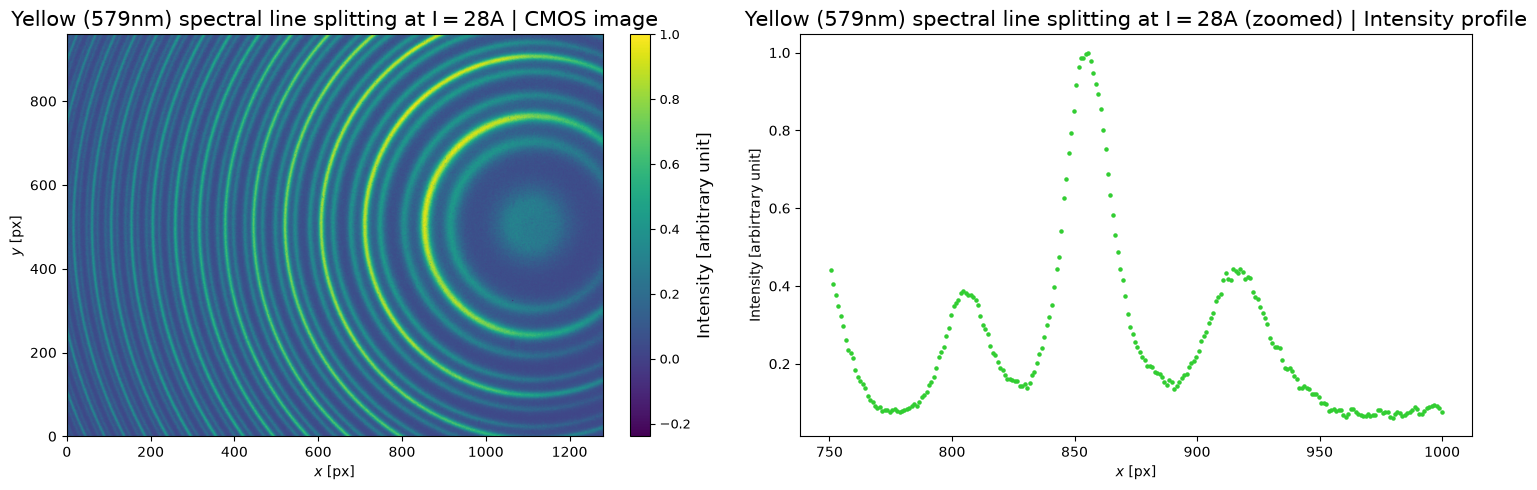

In [29]:
yellow_nopol = "./Measurment Data/Yellow Lines/579nm2s100F Without Pol 28A.dat"
yellow_nopol_image = read_image(yellow_nopol) - read_image(DarkFrame1)/10
yellow_nopol_image[yellow_nopol_image < 100] 
yellow_nopol_image = yellow_nopol_image / yellow_nopol_image.max()
lineOut = image_line(yellow_nopol_image, 500, 15)
lineOut_normal = lineOut / max(lineOut)

view =[750,1000]


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
gr_im=axes[0].imshow(yellow_nopol_image.T, cmap='viridis',origin='lower',aspect=1,vmax=1)
cbar =fig.colorbar(gr_im, ax= axes[0],shrink=1,
    pad=0.04)
cbar.set_label("Intensity [arbitrary unit]",fontsize= 12)
cbar.ax.tick_params(labelsize=9)
axes[0].set_title(r"Yellow (579nm) spectral line splitting at $\mathrm{I} = 28 \mathrm{A}$ | CMOS image",fontsize=15)
axes[0].set_xlabel(r"$x$ [px]")
axes[0].set_ylabel(r"$y$ [px]")

axes[1].scatter(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],lineOut_normal[view[0]:view[1]], color="limegreen",s=5)
axes[1].set_title(r"Yellow (579nm) spectral line splitting at $\mathrm{I} = 28 \mathrm{A}$ (zoomed) | Intensity profile",fontsize=15)
axes[1].set_xlabel(r"$x$ [px]")
axes[1].set_ylabel("Intensity [arbirtrary unit]")
fig.savefig('yellow_Zeeman_579.png')
plt.tight_layout()
plt.show()

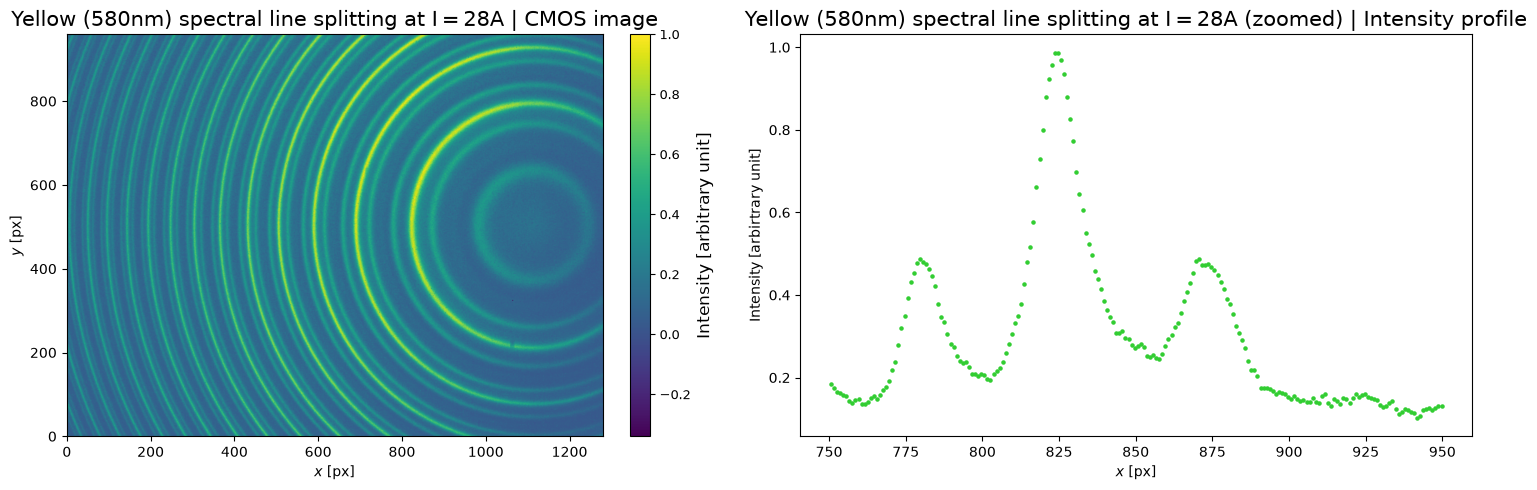

In [30]:
yellow_nopol = "./Measurment Data/Yellow Lines/580nm2s100F Without Pol 28A.dat"
yellow_nopol_image = read_image(yellow_nopol) - read_image(DarkFrame1)/10
yellow_nopol_image[yellow_nopol_image < 100] 
yellow_nopol_image = yellow_nopol_image / yellow_nopol_image.max()
lineOut = image_line(yellow_nopol_image, 500, 15)
lineOut_normal = lineOut / max(lineOut)

view =[750,950]


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
gr_im=axes[0].imshow(yellow_nopol_image.T, cmap='viridis',origin='lower',aspect=1,vmax=1)
cbar =fig.colorbar(gr_im, ax= axes[0],shrink=1,
    pad=0.04)
cbar.set_label("Intensity [arbitrary unit]",fontsize= 12)
cbar.ax.tick_params(labelsize=9)
axes[0].set_title(r"Yellow (580nm) spectral line splitting at $\mathrm{I} = 28 \mathrm{A}$ | CMOS image",fontsize=15)
axes[0].set_xlabel(r"$x$ [px]")
axes[0].set_ylabel(r"$y$ [px]")

axes[1].scatter(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],lineOut_normal[view[0]:view[1]], color="limegreen",s=5)
axes[1].set_title(r"Yellow (580nm) spectral line splitting at $\mathrm{I} = 28 \mathrm{A}$ (zoomed) | Intensity profile",fontsize=15)
axes[1].set_xlabel(r"$x$ [px]")
axes[1].set_ylabel("Intensity [arbirtrary unit]")
fig.savefig('yellow_zeeman_580.png')
plt.tight_layout()
plt.show()

In [10]:
#written with Chatgpt to condese the plotting
def fit_energies_against_reference(
    x, fits, fit_devs, center_value, center_error, wavelength,
    reference_index=4, include_energy=None,
):
    plt.rcParams['text.usetex'] = True
    converted = [
        Convert_Energy(
            np.asarray(fit), center_value, wavelength,
            np.asarray(dev), center_error, centerpixel_dev,
        )
        for fit, dev in zip(fits, fit_devs)
    ]
    energies = [item[0] for item in converted]
    errors = [item[1] for item in converted]

    x = np.asarray(x)

    if include_energy is None:
        include_energy = np.ones(len(energies), dtype=bool)
    else:
        include_energy = np.asarray(include_energy, dtype=bool)

    if len(include_energy) != len(energies):
        raise ValueError("include_energy must have one Boolean per energy")

    reference_energy = energies[reference_index]
    reference_error = errors[reference_index]
    x_fit = np.linspace(x.min(), x.max(), 200)
    results = {}

    for i, (energy, error) in enumerate(zip(energies, errors)):
        if i == reference_index or not include_energy[i]:
            continue

        difference = energy - reference_energy
        difference_error = np.sqrt(error**2 + reference_error**2)

        (coeffs, cov) = np.polyfit(
            x, difference, deg=1,
            w=1 / difference_error,
            cov="unscaled",
        )
        slope, intercept = coeffs
        slope_dev, intercept_dev = np.sqrt(np.diag(cov))

        points = plt.errorbar(
            x, difference, yerr=difference_error,
            fmt="o",
        )
        color = points[0].get_color()

        plt.plot(
            x_fit, slope * x_fit + intercept,
            color=color,
            label=f"Fit E{i + 1}",
        )

        results[i + 1] = {
            "difference": difference,
            "difference_error": difference_error,
            "slope": slope,
            "slope_error": slope_dev,
            "intercept": intercept,
            "intercept_error": intercept_dev,
        }
    plt.xlabel(r"\textbf{$\mu_B  B  \: in  \: \mu eV$}")
    plt.ylabel(r"\textbf{$Relative \: Energy \: in \: \mu eV$}")
    plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    #plt.tight_layout(rect=[0, 0, 0.8, 1])
    plt.show()

    return energies, errors, results

In [11]:
centerpixel = 1119.87117
centerpixel_dev = 1.62799933

fits = [
    x1_fits, x2_fits, x3_fits, x4_fits, x5_fits,
    x6_fits, x7_fits, x8_fits, x9_fits,
]
fit_devs = [
    x1_fits_dev, x2_fits_dev, x3_fits_dev, x4_fits_dev, x5_fits_dev,
    x6_fits_dev, x7_fits_dev, x8_fits_dev, x9_fits_dev,
]

x = np.array([get_mag_strength(15),get_mag_strength(21),
    get_mag_strength(24), get_mag_strength(27), get_mag_strength(30),
])


include_energy = [True, True, True, True, True, True, True, True, True]

energies, energy_errors, fit_results = fit_energies_against_reference(
    x=x,
    fits=fits,
    fit_devs=fit_devs,
    center_value=Results[0]["Value"],
    center_error=Results[0]["Error"],
    wavelength=wavelength,
    reference_index=4,       # Energy 5
    include_energy=include_energy,
)

energy1, error1 = Convert_Energy(np.array(x4_fits), Results[0]["Value"], wavelength, np.array(x4_fits_dev), Results[0]["Error"], centerpixel_dev)
energy2, error2 = Convert_Energy(np.array(x5_fits), Results[0]["Value"], wavelength, np.array(x5_fits_dev), Results[0]["Error"], centerpixel_dev)

print(fit_results[1]["slope"])
print(fit_results[2]["slope"])
print(fit_results[3]["slope"])
print(fit_results[4]["slope"])
print(fit_results[6]["slope"])
print(fit_results[7]["slope"])
print(fit_results[8]["slope"])
print(fit_results[9]["slope"])

pos = [fit_results[2]["slope"],fit_results[3]["slope"],fit_results[4]["slope"]]
print(np.average(pos))





NameError: name 'x1_fits' is not defined

In [12]:
for i in range(len(Results)):
    print(Results[i])

NameError: name 'Results' is not defined